In [1]:
import json, sys
from pathlib import Path
import pandas as pd
from IPython.display import Image, display
sys.path.insert(0, str(Path.cwd().parent / 'python'))
from analysis_common import analytical_src, segment_metrics
from config import AGGREGATE_DIR, AUDIT_DIR, CLEAN_PARQUET, DOCS_DIR, STATS_DIR, VISUALS_DIR, connect
pd.set_option('display.max_columns', 40, 'display.width', 180, 'display.float_format', '{:,.4f}'.format)
con = connect(); src = analytical_src()
kpi = json.loads((AGGREGATE_DIR / 'portfolio_kpis.json').read_text())
fin = json.loads((AGGREGATE_DIR / 'financial_totals.json').read_text())
show = lambda name: display(Image(filename=str(VISUALS_DIR / f'{name}.png')))
csv = lambda name: pd.read_csv(AGGREGATE_DIR / f'{name}.csv')

# 6. Statistical Analysis
Hypothesis tests with assumptions and effect sizes (`python/statistical_analysis.py`). With over a million loans p-values are almost always tiny, so the effect size carries the business meaning.

In [2]:
t = pd.read_csv(STATS_DIR / 'hypothesis_tests.csv'); t[['test_name','test','statistic','p_value_display','effect_size','significant_bonferroni','n']]

,test_name,test,statistic,p_value_display,effect_size,significant_bonferroni,n
0,Grade vs charge-off,Pearson chi-square (df=6),"92,284.2511",<1e-300,Cramer's V = 0.262,True,1345310
1,Term vs charge-off (all resolved),Pearson chi-square (df=1),"41,716.8301",<1e-300,Cramer's V = 0.176,True,1345310
2,"Term vs charge-off, stratified by grade (matur...",Cochran-Mantel-Haenszel,287.8904,<1e-300,Pooled odds ratio 1.19 (95% CI 1.17-1.21),True,776276
3,DTI band trend,Cochran-Armitage trend,119.7743,<1e-300,Rate 14.9% to 30.6%,True,1344896
4,Income band trend,Cochran-Armitage trend,-76.1622,<1e-300,Rate 23.8% to 14.9%,True,1344949
5,FICO band trend,Cochran-Armitage trend,-150.4390,<1e-300,Rate 25.3% to 8.9%,True,1345310
6,Employment length (known values) vs charge-off,Pearson chi-square (df=10),319.4270,1.21e-62,Cramer's V = 0.016,True,1266799
7,"Income verification vs charge-off, stratified ...",Cochran-Mantel-Haenszel,"1,440.4289",<1e-300,Pooled odds ratio 1.22 (95% CI 1.21-1.24),True,1345310
8,Interest rate: Charged Off vs Fully Paid,"Welch t-test, with Mann-Whitney on a sample as...",295.9698,<1e-300,Cohen's d = 0.65; rank AUC = 0.68,True,1345310
9,Loan-level recovery ratio across grades,Kruskal-Wallis,681.3909,6.37e-144,Epsilon-squared = 0.0063,True,107007


In [3]:
pd.set_option('display.max_colwidth', None); t[['test_name','null_hypothesis','alternative_hypothesis','why_selected','assumption_check','business_reading']]

,test_name,null_hypothesis,alternative_hypothesis,why_selected,assumption_check,business_reading
0,Grade vs charge-off,Charge-off is independent of grade,Charge-off depends on grade,Two categorical variables with independent loan outcomes,"Minimum expected cell count 1,823 (needs >= 5)",Moderate association and the strongest single segmenter: rate rises from 6.0% (A) to 49.9% (G).
1,Term vs charge-off (all resolved),Charge-off is independent of term,Charge-off depends on term,Two categorical variables with independent loan outcomes,"Minimum expected cell count 64,792 (needs >= 5)",Unadjusted rate is 16.0% for 36 months against 32.4% for 60 months; see the grade-stratified test.
2,"Term vs charge-off, stratified by grade (mature loans)",Common odds ratio of 60 vs 36 months equals 1 within grades,Common odds ratio differs from 1,"Isolates term from grade mix, because 60-month loans skew to lower grades","Breslow-Day-type homogeneity p=3.31e-14: when small, the pooled ratio is an average across differing grades","Within the same grade, 60-month loans have about 1.19 times the odds of charge-off, so the term effect is smaller than the raw gap but still material."
3,DTI band trend,No linear trend in charge-off rate across ordered DTI bands,A linear trend exists,"Bands are ordered, so a trend test is more powerful than an unordered chi-square","Group sizes 6,732-561,904; large-sample normal approximation holds. 'Unknown' excluded","Charge-off moves steadily across DTI bands from 14.9% to 30.6%. This is an association, not proof that DTI causes default."
4,Income band trend,No linear trend in charge-off rate across ordered income bands,A linear trend exists,"Bands are ordered, so a trend test is more powerful than an unordered chi-square","Group sizes 84,184-355,532; large-sample normal approximation holds. 'Unknown' excluded","Charge-off moves steadily across income bands from 23.8% to 14.9%. This is an association, not proof that income causes default."
5,FICO band trend,No linear trend in charge-off rate across ordered FICO bands,A linear trend exists,"Bands are ordered, so a trend test is more powerful than an unordered chi-square","Group sizes 106,601-459,480; large-sample normal approximation holds. 'Unknown' excluded","Charge-off moves steadily across FICO bands from 25.3% to 8.9%. This is an association, not proof that FICO causes default."
6,Employment length (known values) vs charge-off,Charge-off is independent of employment length,Charge-off depends on employment length,Two categorical variables with independent loan outcomes,"Minimum expected cell count 9,949 (needs >= 5)",Statistically detectable but practically negligible (V=0.016); rates span only 18.8%-20.6%. Missing employment length (26.9%) separates more than any stated length.
7,"Income verification vs charge-off, stratified by grade",Common odds ratio of verified vs not verified equals 1 within grades,Common odds ratio differs from 1,"Verification is targeted at riskier applicants, so raw comparison is confounded with grade",Large cell counts in every grade stratum,"Pooled across grades, verified loans carry higher charge-off odds. Verification is not evidence of lower risk here; a plausible explanation is that it targets applicants already considered riskier (selection), which this data cannot confirm."
8,Interest rate: Charged Off vs Fully Paid,Mean interest rate is equal for both outcomes,Means differ,Compares a continuous value between two groups with unequal variances,"Rates are not normal, but n is huge so the mean is approximately normal (CLT); Mann-Whitney on 302,715 sampled loans p=0 agrees","Charged-off loans carried 3.09 percentage points higher rates on average. Pricing reflects risk ordering, and it also raises the payment burden; the direction of cause cannot be separated here."
9,Loan-level recovery ratio across grades,Recovery-ratio distribution is the same across grades,At least one grade differs,"Ratios are heavily zero-inflated and non-normal,

In [4]:
pd.read_csv(STATS_DIR / 'confidence_intervals.csv')

,estimate,charged_off,resolved,default_rate,ci_low_95,ci_high_95
0,All resolved loans (primary),268559,1345310,0.1996,0.1990,0.2003
1,Mature loans only,117610,776276,0.1515,0.1507,0.1523
2,Grade A,14201,235090,0.0604,0.0595,0.0614
3,Grade B,52569,392741,0.1339,0.1328,0.1349
4,Grade C,85649,381686,0.2244,0.2231,0.2257
5,Grade D,61054,200953,0.3038,0.3018,0.3058
6,Grade E,36035,93650,0.3848,0.3817,0.3879
7,Grade F,14491,32058,0.4520,0.4466,0.4575
8,Grade G,4560,9132,0.4993,0.4891,0.5096
9,Term 36 months,163252,1020743,0.1599,0.1592,0.1606


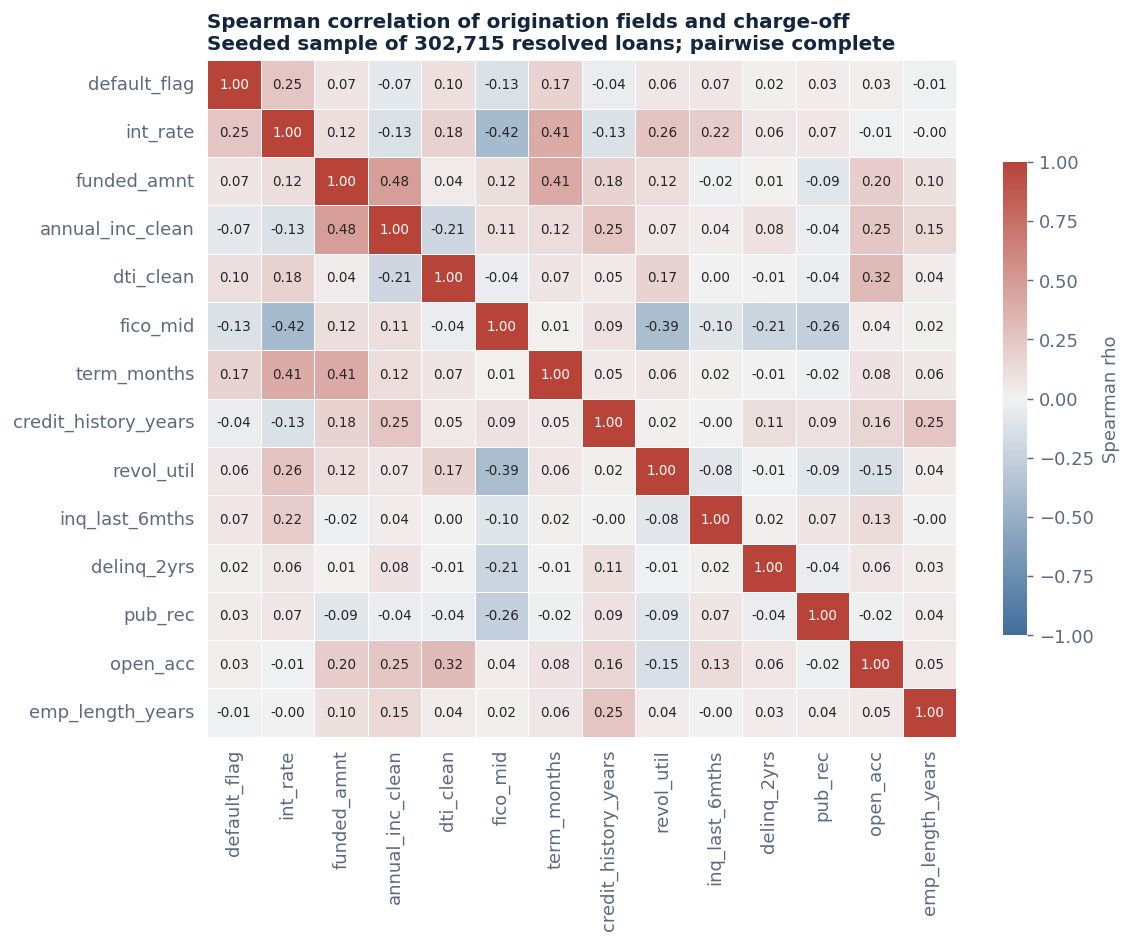

In [5]:
show('s_correlation_heatmap')

In [6]:
pd.read_csv(STATS_DIR / 'distribution_outliers.csv')[['column','median','max','skewness','iqr_outliers','iqr_outlier_pct']]

,column,median,max,skewness,iqr_outliers,iqr_outlier_pct
0,funded_amnt,"12,875.0000","40,000.0000",0.7788,35215,0.0156
1,int_rate,12.6200,30.9900,0.7681,41099,0.0182
2,annual_inc,"65,000.0000","110,000,000.0000",493.8861,110041,0.0487
3,dti,17.8400,999.0000,29.2019,21580,0.0096
4,revol_util,50.3000,892.3000,0.0126,114,0.0001
5,revol_bal,"11,324.0000","2,904,836.0000",13.2320,137095,0.0606
6,open_acc,11.0000,101.0000,1.3155,84754,0.0375
7,delinq_2yrs,0.0000,58.0000,5.9298,421531,0.1865
8,pub_rec,0.0000,86.0000,11.3768,357881,0.1583
9,total_acc,22.0000,176.0000,1.0075,39411,0.0174


Adjusted odds ratios describe association after controlling for the other fields. This is not a credit-scoring model.

In [7]:
pd.read_csv(STATS_DIR / 'adjusted_odds_ratios.csv')

,term,odds_ratio,ci_low_95,ci_high_95,p_value,n,pseudo_r2
0,Intercept,17.1039,10.1773,28.7447,0.0000,174836,0.0585
1,"C(grade, Treatment('A'))[T.B]",1.7951,1.7011,1.8944,0.0000,174836,0.0585
2,"C(grade, Treatment('A'))[T.C]",2.8228,2.6711,2.9832,0.0000,174836,0.0585
3,"C(grade, Treatment('A'))[T.D]",3.7756,3.5555,4.0093,0.0000,174836,0.0585
4,"C(grade, Treatment('A'))[T.E]",4.6374,4.3144,4.9846,0.0000,174836,0.0585
5,"C(grade, Treatment('A'))[T.F]",5.5070,4.9847,6.0840,0.0000,174836,0.0585
6,"C(grade, Treatment('A'))[T.G]",7.6157,6.3389,9.1497,0.0000,174836,0.0585
7,term60,1.3723,1.3127,1.4347,0.0000,174836,0.0585
8,dti_clean_scaled,1.1618,1.1431,1.1808,0.0000,174836,0.0585
9,fico_mid_scaled,0.9071,0.8964,0.9179,0.0000,174836,0.0585
